# Banknote classification and explanability as regional evidence

Fake Banknote detection is a challenging task among the world, as a prevailing topic in AI in finance. This project will reimplement some existing classifications to identiy fake bank note and propose a customized explainability algorithm to compare with existing explainability algorithms.

**Part 1 · Compare 4 classifiers (Sections 1–7).** Prepare the images, train the models, read each epoch and compare the results on the same 53 test images.

**Part 2 · Explain the classification (Sections 8–13).** Use ResNet18 to reproduce a missed 100-rupee example. Compare Grad-CAM and Score-CAM, then propose a varied algorith to test candidate regions by changing their regional pixels. A 2000-rupee example compares two ways to select a region.

Run the notebook from top to bottom. By default, it reads the 12 recorded training histories and computes both regional examples. Set `TRAIN_AGAIN` to fit the 4 classifiers again, or `RUN_FULL_VALIDATION` to recompute the CAM metrics for all images.
Saved training histories and cached validation tables use the earlier resize filter. Fresh runs and the two regional examples use OpenCV linear resizing.

In [1]:
import hashlib
import json
import random
import time
from pathlib import Path
from tempfile import TemporaryDirectory, mkdtemp

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib.patches import Patch
from pytorch_grad_cam import GradCAM, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF
from torchvision.models import (
    EfficientNet_V2_S_Weights, ResNet18_Weights, efficientnet_v2_s, resnet18,
)

TRAIN_AGAIN = False     # Fit four models with three seeds each.
RUN_FULL_VALIDATION = False  # Recompute both CAMs on 32 pilot validation images.
RUN_DEMOS = False       # Optional short CNN exercise and CAM checkpoint.
RECHECK_RANKING = False # Optional replay of the old/new test comparison.


Matplotlib is building the font cache; this may take a moment.


In [2]:
DATA = Path("dataset_archive_course_v3")
PILOT_DATA = Path("dataset_archive_pilot_v2")
RESNET = Path("runs/archive_pilot_v2/resnet18/best.pt")
COMPARISON = Path("runs/course_models_archive_v3")
SEED = 42
BATCH_SIZE = 32
DEMO_EPOCHS = 3
EPOCHS = 30
LR = 1e-3
CLASS_NAMES = ["fake money", "OR money", "not a banknote"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
DISPLAY_NAMES = {"fake money": "Fake Money", "OR money": "Real Money", "not a banknote": "Not a Banknote"}
names = [DISPLAY_NAMES[label] for label in CLASS_NAMES]
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
TRANSFER_MODELS = ("resnet18", "efficientnet_v2_s", "dinov3_vits16")
DINO_TIMM_MODEL = "vit_small_patch16_dinov3.lvd1689m"


MODEL_NAMES = {"cnn": "CNN", "resnet18": "ResNet18", "efficientnet_v2_s": "EfficientNetV2-S",
               "dinov3_vits16": "DINOv3 ViT-S/16"}
METRICS = ["accuracy", "balanced_accuracy", "fake_recall", "fake_fnr", "fake_precision",
           "real_false_alarm_rate", "not_banknote_recall", "not_banknote_as_fake_rate"]


def read_rgb(path):
    """Load a photograph as RGB, keeping the stored pixel orientation."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if bgr is None and Path(path).suffix.lower() == ".avif":
        # Some OpenCV builds decode AVIF only through the FFmpeg backend.
        reader = cv2.VideoCapture(str(path), cv2.CAP_FFMPEG)
        _, bgr = reader.read()
        reader.release()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


## 1. Image category

The following part shows the 3 categories for this project: real, fake, and not a bank note. Numbers of test/val/train are shown below with training images and paths as examples.

split,train,val,test
label,,,
Fake Money,83,17,24
Not a Banknote,22,4,4
Real Money,82,17,25


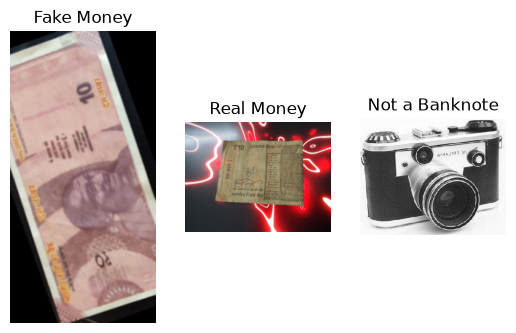

,label,split_path
0,Fake Money,train/fake money/10_3013738dc9732936.jpeg
124,Real Money,train/OR money/10_9b1ec45648e42474.jpg
248,Not a Banknote,train/not a banknote/camera_image_0045.jpg


In [3]:
def show_photos(files, captions):
    plt.figure()
    for i, (path, caption) in enumerate(zip(files, captions), start=1):
        plt.subplot(1, len(files), i)
        plt.imshow(read_rgb(DATA / path))
        plt.title(caption)
        plt.axis("off")
    plt.show()


paths = pd.read_csv(DATA / "image_paths.csv", usecols=["split", "label", "split_path"])
paths["label"] = paths["label"].map(DISPLAY_NAMES)
display(pd.crosstab(paths["label"], paths["split"])[["train", "val", "test"]])

examples = paths[paths["split"] == "train"].drop_duplicates("label")
show_photos(examples["split_path"], examples["label"])
display(examples[["label", "split_path"]])

## 2. Prepare the enviornment and image for the model

First choose the device and set the random seed so the training runs can be repeated.

In [4]:
def set_seed(seed):
    """Seed the Python, NumPy and PyTorch random generators for repeatable training runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    """Choose the first available device in the order CUDA, Apple MPS, then CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

The CNN takes 64 × 64 images. The three pretrained models take 224 × 224 images. Save the preprocessing name with each checkpoint so we know how to prepare new photos.

In [5]:
INPUT_FORMATS = {
    "cnn": "RGB_letterbox_64_scale_0_1",
    "resnet18": "ResNet18_RGB_letterbox_224_ImageNetNorm",
    "efficientnet_v2_s": "EfficientNetV2S_RGB_letterbox_224_ImageNetNorm",
    "dinov3_vits16": "DINOv3ViTS16_RGB_letterbox_224_ImageNetNorm",
}


def preprocessing_config(architecture):
    """Record the input size and normalization for this model."""
    return {"img_size": 64 if architecture == "cnn" else 224,
            "resize_interpolation": "cv2.INTER_LINEAR",
            "preprocessing": INPUT_FORMATS[architecture]}

**Fit the whole note.** Compute the dimensions and center position, keeping the original aspect ratio. The next cell uses OpenCV bilinear interpolation.

In [6]:
def fit_square(original_size, target_size):
    """Resize the long side to target_size and center the image in the square."""
    width, height = original_size
    scale = target_size / max(width, height)
    width = max(1, round(width * scale))
    height = max(1, round(height * scale))
    left = (target_size - width) // 2
    top = (target_size - height) // 2
    return {"resized_size_wh": (width, height),
            "content_box_xyxy": (left, top, left + width, top + height)}

**Make the model input.** Convert RGB values to a tensor, normalize the channels for pretrained models, and place the photo on a square canvas. Keep its bounds so the later CAM experiment can exclude the padding.

In [7]:
class TestTransform:
    def __init__(self, architecture="cnn"):
        self.size = preprocessing_config(architecture)["img_size"]
        self.normalize = architecture in TRANSFER_MODELS

    def with_geometry(self, image):
        height, width = image.shape[:2]
        geometry = fit_square((width, height), self.size)
        left, top, right, bottom = geometry["content_box_xyxy"]
        rgb = cv2.resize(image, geometry["resized_size_wh"], interpolation=cv2.INTER_LINEAR)
        pixels = TF.to_tensor(rgb)
        if self.normalize:
            pixels = TF.normalize(pixels, IMAGENET_MEAN, IMAGENET_STD)

        square = pixels.new_zeros((3, self.size, self.size))
        square[:, top:bottom, left:right] = pixels
        return square, geometry

    def __call__(self, image):
        return self.with_geometry(image)[0]

**Training only.** Adjust brightness by scaling the pixels, then adjust contrast around the mean grayscale intensity. Apply the usual resize and padding. Validation and test images skip these random edits.

In [8]:
class TrainAug(TestTransform):
    """Randomly adjust brightness and contrast before the usual image transform."""
    def __call__(self, image):
        brightness = random.uniform(0.9, 1.1)
        image = np.clip(image.astype(np.float32) * brightness, 0, 255).astype(np.uint8)

        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        center = int(cv2.mean(gray)[0] + 0.5)
        contrast = random.uniform(0.9, 1.1)
        pixels = center + (image.astype(np.float32) - center) * contrast
        return super().__call__(np.clip(pixels, 0, 255).astype(np.uint8))


**Load a split.** Each class folder supplies a label. The dataset stores the paths in order and reads each photo when a training batch needs it.

In [9]:
def list_images(folder):
    """Return sorted image paths from one class folder so each run visits the same files."""
    # The pilot training manifest includes an AVIF photograph.
    extensions = {".jpg", ".jpeg", ".png", ".avif"}
    return [str(p) for p in sorted(Path(folder).iterdir())
            if p.is_file() and p.suffix.lower() in extensions]


class MoneyDataset(Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform or TestTransform()
        self.samples = [(path, label) for label, name in enumerate(CLASS_NAMES)
                        for path in list_images(Path(root) / name)]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        return self.transform(read_rgb(path)), label

**Check one input.** Run the same photo through both input sizes. The first dimension should be 3 for RGB.

In [10]:
photo = read_rgb(DATA / examples.iloc[0]["split_path"])
for architecture in ("cnn", "resnet18"):
    image = TestTransform(architecture)(photo)
    print(MODEL_NAMES[architecture], "input shape (channels, height, width):", tuple(image.shape))

CNN input shape (channels, height, width): (3, 64, 64)
ResNet18 input shape (channels, height, width): (3, 224, 224)


## 3. Build the four classifiers

**Start with the CNN baseline.** Follow one 64 × 64 RGB image through three convolution and pooling blocks. Each pooling step halves its width and height, leaving 32 maps of size 8 × 8. The classifier turns them into three scores for fake money, real money and non-banknotes.

In [12]:
class FakeMoneyCNN(nn.Module):
    """Classify 64-by-64 RGB photographs using three convolution and pooling blocks."""
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

**Choose a model and decide what learns.** The CNN trains all its weights. For each pretrained model, find the line that replaces its final layer with a three-class output. The last three lines before the return freeze the feature extractor and enable training for the classification head.

In [ ]:
def classification_head(model):
    """Name of the module trained on the banknote labels."""
    return {"resnet18": "fc", "efficientnet_v2_s": "classifier",
            "dinov3_vits16": "head"}[model.architecture]


def build_model(architecture="cnn", pretrained=False):
    classes = len(CLASS_NAMES)
    if architecture == "cnn":
        model = FakeMoneyCNN(classes)
    elif architecture == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, classes)
    elif architecture == "efficientnet_v2_s":
        weights = EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_v2_s(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, classes)
    elif architecture == "dinov3_vits16":
        model = timm.create_model(DINO_TIMM_MODEL, pretrained=pretrained, img_size=224, num_classes=0)
        model.head = nn.Linear(model.num_features, classes)

    model.architecture = architecture
    if architecture in TRANSFER_MODELS:
        model.requires_grad_(False)
        getattr(model, classification_head(model)).requires_grad_(True)
    return model

**Record the starting weights.** The CNN starts from random weights, ResNet18 and EfficientNetV2-S start from ImageNet weights, and DINOv3 uses pretrained transformer weights. Section 4 saves this information with the training run.

In [ ]:
def initialization_metadata(architecture):
    """Describe this architecture's training initialization for the experiment record."""
    if architecture == "dinov3_vits16":
        return {"initial_weights": "DINOv3_LVD1689M_timm", "model_variant": DINO_TIMM_MODEL}
    return {"initial_weights": "IMAGENET1K_V1" if architecture in TRANSFER_MODELS else "random",
            "model_variant": architecture}

## 4. Train on batches and select an epoch

**Train for one epoch.** For each batch, predict the three class scores, measure cross-entropy loss, and update the trainable weights. The CNN trains all layers. For the transfer models, keep the backbone in evaluation mode and train only the head. Average the loss and accuracy over the images seen.

In [14]:
def train_one_epoch(model, loader, optimizer, device):
    """Run one pass over the training photos and return mean loss and accuracy."""
    if model.architecture in TRANSFER_MODELS:
        # Freeze BatchNorm, stochastic depth and backbone dropout during head training.
        model.eval()
        getattr(model, classification_head(model)).train()
    else:
        model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return loss_sum / total, correct / total

### Count classification errors

Read across each row of the confusion matrix for one folder label. Fake recall counts how many labelled fakes the model caught. Fake precision counts how many of its fake alerts were correct. The real false alarm rate counts real notes flagged as fake.

In [15]:
def classification_metrics(labels, probabilities):
    """Count three-class decisions. Rows are folder labels and columns are predictions."""
    predictions = np.argmax(probabilities, axis=1)
    cm = np.zeros((3, 3), dtype=int)
    np.add.at(cm, (labels, predictions), 1)
    fake, real, other = cm.tolist()
    n_fake, n_real, n_other = cm.sum(axis=1).tolist()
    predicted_fake = int(cm[:, 0].sum())
    recalls = [fake[0] / n_fake, real[1] / n_real, other[2] / n_other]
    return {
        "n": len(labels), "accuracy": int(cm.trace()) / len(labels),
        "balanced_accuracy": sum(recalls) / 3, "confusion_matrix": cm.tolist(),
        "fake_recall": recalls[0], "fake_fnr": (fake[1] + fake[2]) / n_fake,
        "fake_precision": fake[0] / predicted_fake if predicted_fake else None,
        "real_recall": recalls[1], "real_false_alarm_rate": real[0] / n_real,
        "not_banknote_recall": recalls[2], "not_banknote_as_fake_rate": other[0] / n_other,
        "fake_as_real_rate": fake[1] / n_fake, "fake_as_not_banknote_rate": fake[2] / n_fake,
    }

**Evaluate one split.** Run the model on every batch without updating weights. Average the loss over all images. Request the individual probabilities when you need to inspect particular mistakes.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, device, *, return_predictions=False):
    """Compute split metrics and optionally return labels and probabilities in image order."""
    model.eval()
    labels_all, probs_all = [], []
    loss_sum = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        labels_all.extend(labels.cpu().tolist())
        probs_all.extend(logits.softmax(dim=1).cpu().tolist())
    metrics = classification_metrics(labels_all, probs_all)
    metrics["loss"] = loss_sum / metrics["n"]
    if return_predictions:
        return metrics, labels_all, probs_all
    return metrics

**Reload a saved model.** A checkpoint contains the architecture name and the learned weights. Build that architecture, load the weights, then switch to evaluation mode. Return the checkpoint too so later cells can read the selected epoch and its validation scores.

In [16]:
def load_checkpoint(path, device):
    """Load a three-class course checkpoint and switch the classifier to evaluation mode."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = build_model(checkpoint["architecture"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, checkpoint


### Prepare a training run

Shuffle and augment the training photos. Keep validation photos in a fixed order. Save the model and image settings with each checkpoint so the weights can be loaded later.

In [ ]:
def training_loaders(data_dir, architecture, batch_size, seed):
    root = Path(data_dir)
    train_images = MoneyDataset(root / "train", transform=TrainAug(architecture))
    val_images = MoneyDataset(root / "val", transform=TestTransform(architecture))
    shuffle_order = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_images, batch_size=batch_size, shuffle=True, generator=shuffle_order)
    val_loader = DataLoader(val_images, batch_size=batch_size)
    return train_loader, val_loader


def checkpoint_settings(architecture, seed, batch_size, data_dir):
    return {
        "architecture": architecture, "seed": seed, "batch_size": batch_size,
        **preprocessing_config(architecture), **initialization_metadata(architecture),
        "class_to_idx": CLASS_TO_IDX, "resize_mode": "letterbox", "decision_rule": "argmax",
        "training_mode": "frozen_backbone_head_only" if architecture in TRANSFER_MODELS else "all_parameters",
        "learning_rate": LR, "fake_threshold": 0.5, "selection_metric": "val_loss",
        "data_dir": str(Path(data_dir).resolve()),
    }

### Select the best epoch

Follow the loop: train for one epoch, evaluate on validation photos, and save the weights if validation loss improves. After eight epochs without improvement by default, stop and reload the best weights. Section 5 uses the saved history to compare runs.

In [ ]:
def train(epochs=EPOCHS, data_dir=DATA, output_dir=None, patience=8,
          device=None, seed=SEED, architecture="cnn", batch_size=BATCH_SIZE):
    """Fit one model and return its best validation checkpoint as a model, plus its history."""
    set_seed(seed)
    device = torch.device(device or get_device())
    train_loader, val_loader = training_loaders(data_dir, architecture, batch_size, seed)
    model = build_model(architecture, pretrained=architecture in TRANSFER_MODELS).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    folder = Path(output_dir or f"runs/threeclass_{architecture}_letterbox")
    folder.mkdir(parents=True, exist_ok=True)
    checkpoint = folder / "best.pt"
    settings = checkpoint_settings(architecture, seed, batch_size, data_dir)
    records = []
    best_loss, best_epoch = float("inf"), 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        loss, accuracy = train_one_epoch(model, train_loader, optimizer, device)
        val = evaluate(model, val_loader, device)
        records.append({"epoch": epoch, "train_loss": loss, "train_accuracy": accuracy, "val": val})
        print(f"Epoch {epoch}/{epochs}  train loss {loss:.4f}  val loss {val['loss']:.4f}  "
              f"fake recall {val['fake_recall']:.3f}  real false alarm {val['real_false_alarm_rate']:.3f}")

        if val["loss"] < best_loss:
            best_loss, best_epoch = val["loss"], epoch
            torch.save({**settings, "epoch": epoch, "val_metrics": val,
                        "model_state_dict": model.state_dict()}, checkpoint)
        if epoch - best_epoch >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    history = {key: settings[key] for key in ("architecture", "seed", "batch_size", "preprocessing", "resize_mode")}
    history.update(epochs=records, device=str(device), training_seconds=time.perf_counter() - started)
    (folder / "history.json").write_text(json.dumps(history, indent=2))
    best_model, _ = load_checkpoint(checkpoint, device)
    print(f"Best epoch {best_epoch}: {checkpoint}")
    return best_model, history

## 5. Train the four models and read the epoch logs

Run each model with seeds 42, 43 and 44. The split, batch size, optimizer and stopping rule are shared across runs. In training mode, the next cell fits all 12 models before evaluating any test images. In replay mode, it opens the run folder supplied with the project.


In [18]:
seeds = [42, 43, 44]
archs = list(MODEL_NAMES)
device = get_device()
torch.set_num_threads(2)

if TRAIN_AGAIN:
    run_root = Path(mkdtemp(prefix="course_models_", dir=COMPARISON.parent))
    print("Writing new training runs to", run_root)
    for arch in archs:
        for seed in seeds:
            folder = run_root / arch / f"seed_{seed}"
            train(EPOCHS, DATA, folder, device=device, seed=seed, architecture=arch)
else:
    run_root = COMPARISON
    print("Reading recorded training runs from", run_root)


Reading recorded training runs from runs/course_models_archive_v3


### Follow each run from its first epoch to its last

Each table follows one model and one seed. Read down the training loss column to see how the fit changes. Then find the lowest validation loss. The star marks the checkpoint used for testing. For the recorded CNN run with seed 42, epoch 19 was selected and training continued through epoch 27.


In [19]:
runs = []
for arch in archs:
    for seed in seeds:
        folder = run_root / arch / f"seed_{seed}"
        history = json.loads((folder / "history.json").read_text())
        epochs = history["epochs"]
        best = min(epochs, key=lambda row: row["val"]["loss"])
        print(f"{MODEL_NAMES[arch]} | seed {seed} | selected epoch {best['epoch']}")
        rows = []
        for row in epochs:
            rows.append({"Epoch": row["epoch"], "Train loss": row["train_loss"],
                         "Train acc": row["train_accuracy"], "Val loss": row["val"]["loss"],
                         "Val acc": row["val"]["accuracy"], "Val fake recall": row["val"]["fake_recall"],
                         "Val real false alarm": row["val"]["real_false_alarm_rate"],
                         "Selected": "*" if row["epoch"] == best["epoch"] else ""})
        display(pd.DataFrame(rows).set_index("Epoch").round(4))
        runs.append({"architecture": arch, "seed": seed, "best_epoch": best["epoch"],
                     "training_seconds": history["training_seconds"],
                     "checkpoint": str((folder / "best.pt").relative_to(run_root))})


CNN | seed 42 | selected epoch 19


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0708,0.4439,1.0047,0.4474,1.0000,1.0000,
2,0.9863,0.5027,0.9807,0.4474,0.0000,0.0000,
3,0.9945,0.4385,0.9666,0.6053,0.8824,0.5294,
4,0.9700,0.5027,0.9585,0.4474,1.0000,1.0000,
5,0.9590,0.5294,0.9382,0.6579,0.5882,0.1176,
6,0.9363,0.6203,0.8991,0.6316,0.8235,0.4118,
7,0.8782,0.6417,0.8484,0.6316,0.8235,0.4118,
8,0.8207,0.6310,0.8093,0.5789,0.7059,0.4118,
9,0.7931,0.6524,0.7874,0.6842,0.7647,0.2353,


CNN | seed 43 | selected epoch 15


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0585,0.3583,0.9851,0.4474,1.0000,1.0000,
2,0.9839,0.4439,0.9719,0.4474,1.0000,1.0000,
3,0.9743,0.4545,0.9640,0.6053,0.7647,0.4118,
4,0.9584,0.4759,0.9480,0.6053,0.8235,0.4706,
5,0.9283,0.6417,0.9293,0.6316,0.7647,0.3529,
6,0.8984,0.6043,0.8754,0.6053,0.8235,0.4706,
7,0.8314,0.6417,0.8329,0.6053,0.8235,0.4706,
8,0.8110,0.6471,0.8310,0.6316,0.5294,0.1176,
9,0.7461,0.6684,0.7892,0.6579,0.8824,0.4118,


CNN | seed 44 | selected epoch 23


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0289,0.4439,0.9919,0.4474,1.0000,1.0000,
2,1.0019,0.4278,0.9761,0.4474,0.0000,0.0000,
3,0.9935,0.4385,0.9948,0.4474,0.0000,0.0000,
4,0.9895,0.4385,0.9606,0.4474,0.0000,0.0000,
5,0.9557,0.4920,0.9477,0.5000,1.0000,0.8824,
6,0.9338,0.5936,0.9171,0.6316,0.7647,0.3529,
7,0.8889,0.6364,0.8716,0.6316,0.8235,0.4118,
8,0.8510,0.6524,0.8550,0.6579,0.7647,0.2941,
9,0.7863,0.6845,0.8019,0.6316,0.8235,0.4118,


... (14 outputs left out)

DINOv3 ViT-S/16 | seed 43 | selected epoch 30


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,1.0771,0.3957,0.9827,0.5000,0.5882,0.4706,
2,0.9323,0.6043,0.8827,0.5000,0.5882,0.4706,
3,0.8530,0.6524,0.8243,0.6579,0.7059,0.2353,
4,0.7981,0.7005,0.7851,0.6579,0.7059,0.2353,
5,0.7567,0.7326,0.7536,0.6842,0.7059,0.1765,
6,0.7205,0.7326,0.7255,0.6842,0.7059,0.1765,
7,0.6867,0.7326,0.7015,0.6842,0.7059,0.1765,
8,0.6559,0.7594,0.6767,0.6842,0.7059,0.1765,
9,0.6275,0.7701,0.6542,0.7368,0.7647,0.1765,


DINOv3 ViT-S/16 | seed 44 | selected epoch 30


,Train loss,Train acc,Val loss,Val acc,Val fake recall,Val real false alarm,Selected
Epoch,,,,,,,
1,0.9763,0.5348,0.9163,0.5789,0.6471,0.3529,
2,0.8897,0.6578,0.8523,0.6579,0.8235,0.3529,
3,0.8290,0.6898,0.8097,0.7105,0.8235,0.2353,
4,0.7818,0.7326,0.7748,0.7368,0.8235,0.1765,
5,0.7421,0.7487,0.7433,0.7368,0.8235,0.1765,
6,0.7042,0.7647,0.7158,0.7368,0.8235,0.1765,
7,0.6684,0.7701,0.6902,0.7368,0.8235,0.1765,
8,0.6382,0.7701,0.6657,0.7632,0.8235,0.1765,
9,0.6084,0.7807,0.6442,0.7632,0.8235,0.1765,


## 6. Compare the models on the same 53 test photographs

The CNN learns from scratch on 64 × 64 images. ResNet18, EfficientNetV2-S and DINOv3 train a classification head on frozen pretrained features at 224 × 224. All four use full-frame letterboxing, Adam, the same split and a 30-epoch limit. The lowest validation loss selects each checkpoint.

Each selected checkpoint is evaluated on the same 53 test images. The dataset labels 24 as fake, 25 as real and 4 as non-banknotes.

| Table column | How to read it |
| --- | --- |
| Accuracy | Out of all 53 images, what percentage got the correct label? Higher is better. |
| Fake recall | Out of the 24 images labelled fake, what percentage did the model catch? Higher is better. |
| Missed fakes | Out of those same 24 images, what percentage did the model call real or non-banknote? This is 100% minus fake recall. Lower is better. |
| Real flagged fake | Out of the 25 images labelled real, what percentage did the model call fake? Lower means fewer false alarms. |
| Fake precision | Of all the images the model called fake, what percentage had a fake label in the dataset? Higher means a fake alert is more often correct. |
| Seconds per fit | Average time in seconds to train the model once. A smaller number means faster training. |

For example, in the recorded EfficientNetV2-S run with seed 42, the model caught 23 of the 24 fake-labelled images. It also flagged 4 real-labelled images. Its fake recall was 23/24 (95.8%), and its fake precision was 23/27 (85.2%).

The table averages three training runs with seeds 42, 43 and 44. A fake recall of 93.1 ± 2.4% means the average was 93.1% and the sample standard deviation across runs was 2.4 percentage points. A smaller spread means the runs gave more similar results on these images.

In the plots below, validation loss measures how well the predicted probabilities fit the validation labels (lower is better). Non-banknote recall is the percentage of the 4 non-banknote test images correctly identified. In each confusion matrix, read across a row for a dataset label and down a column for a prediction. For example, the Real row and Fake column shows false alarms. Counts can be fractional because the plot averages three runs.

### 6.1 Match each prediction to a photograph

For each photo, record its file path, folder label and predicted class. Keeping the test images in order lets us find the exact photo behind a missed fake or a false alarm.

In [22]:
def evaluate_split(model, dataset, device, batch_size):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    metrics, labels, probabilities = evaluate(model, loader, device, return_predictions=True)
    rows = []
    for (path, _), label, probs in zip(dataset.samples, labels, probabilities):
        rows.append({"path": path, "true_label": label, "predicted_label": int(np.argmax(probs)),
                     "probabilities": probs, "p_fake": probs[0], "p_real": probs[1]})
    return metrics, rows

### 6.2 Average the results across training seeds

For each metric, report its mean, sample standard deviation and number of usable runs. For example, precision is undefined when a seed produces no fake alerts.

In [23]:
def metric_summary(table):
    stats = {}
    for name in METRICS:
        values = table[name].dropna().to_numpy(dtype=float)
        stats[name] = {"mean": float(values.mean()) if len(values) else None,
                       "sd": float(values.std(ddof=1)) if len(values) > 1 else None,
                       "defined_runs": len(values)}
    return stats

### 6.3 Compare models trained with the same seed

Build one table per model, with a row for each seed. Subtract the CNN and ResNet18 scores seed by seed before summarizing the differences in percentage points.

In [24]:
def summarize(results):
    summary = {}
    for split in ("val", "test"):
        scores = {}
        for arch in results["protocol"]["models"]:
            rows = {r["seed"]: r[split] for r in results["runs"] if r["architecture"] == arch}
            scores[arch] = pd.DataFrame.from_dict(rows, orient="index").reindex(columns=METRICS)
        table = {arch: metric_summary(frame) for arch, frame in scores.items()}

        gaps = {}
        for baseline in ("cnn", "resnet18"):
            if baseline not in scores:
                continue
            for arch, frame in scores.items():
                if arch != baseline:
                    delta = frame - scores[baseline].loc[frame.index]
                    gaps[f"{arch}_minus_{baseline}"] = metric_summary(100 * delta)
        table["paired_deltas_percentage_points"] = gaps
        summary[split] = table
    return summary

### 6.4 Plot validation loss and test scores

The left panel shows one validation-loss curve per run. The right panel compares four test metrics. Bar height is the seed average and error bars show the sample standard deviation.

In [25]:
def plot_comparison(results, output):
    """Plot validation loss and four test metrics across seeds."""
    models = results["protocol"]["models"]
    fig = Figure(figsize=(14, 5))
    loss_ax, score_ax = fig.subplots(1, 2)
    for run in results["runs"]:
        arch, seed = run["architecture"], run["seed"]
        history_path = output / arch / f"seed_{seed}" / "history.json"
        epochs = json.loads(history_path.read_text())["epochs"]
        loss_ax.plot([e["epoch"] for e in epochs], [e["val"]["loss"] for e in epochs],
                     label=f"{MODEL_NAMES[arch]} / {seed}", alpha=.8)
    keys = ["accuracy", "fake_recall", "real_false_alarm_rate", "not_banknote_recall"]
    x = np.arange(len(keys))
    width = .8 / len(models)
    for i, arch in enumerate(models):
        stats = [results["summary"]["test"][arch][k] for k in keys]
        score_ax.bar(x + (i - (len(models) - 1) / 2) * width,
                    [v["mean"] * 100 for v in stats], width, label=MODEL_NAMES[arch],
                    yerr=[(v["sd"] or 0) * 100 for v in stats], capsize=2)
    loss_ax.set(xlabel="Epoch", ylabel="Validation loss")
    score_ax.set_xticks(x, ["Accuracy", "Fake recall", "Real false alarm", "Not-banknote recall"], rotation=12)
    score_ax.set(ylabel="Test (%)", ylim=(0, 130), title="Fixed split; mean ± seed SD")
    for ax in (loss_ax, score_ax):
        ax.legend(fontsize=7)
        ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    fig.savefig(output / "comparison.png", dpi=160)

### 6.5 Plot the confusion matrices

Average the three confusion matrices for each model. The Fake row and Real column count missed fake-labelled notes classified as real.

In [26]:
def plot_confusion_matrices(results, output):
    models = results["protocol"]["models"]
    names = ["Fake", "Real", "Non-banknote"]
    fig = Figure(figsize=(4 * len(models), 4))
    axes = fig.subplots(1, len(models), squeeze=False)
    for ax, arch in zip(axes[0], models):
        cm = np.mean([r["test"]["confusion_matrix"] for r in results["runs"] if r["architecture"] == arch], axis=0)
        ax.imshow(cm, cmap="Blues", vmin=0)
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")
        ax.set(xticks=range(len(cm)), yticks=range(len(cm)), xticklabels=names, yticklabels=names,
               xlabel="Predicted", ylabel="True", title=MODEL_NAMES[arch])
    fig.suptitle("Test confusion matrices: mean counts across seeds")
    fig.tight_layout()
    fig.savefig(output / "confusion_matrices.png", dpi=160)

### 6.6 Save the comparison files

Keep per-image predictions in JSON, one row per training run in CSV, and the two figures alongside them.

In [27]:
def save_comparison(results, output):
    """Save the per-seed measurements, summary statistics and comparison figures."""
    results["summary"] = summarize(results)
    (output / "comparison.json").write_text(json.dumps(results, indent=2))
    rows = []
    for run in results["runs"]:
        row = {"model": run["architecture"], "seed": run["seed"], "best_epoch": run["best_epoch"],
               "training_seconds": run["training_seconds"]}
        for split in ("val", "test"):
            row.update({f"{split}_{metric}": run[split].get(metric) for metric in METRICS})
        rows.append(row)
    pd.DataFrame(rows).to_csv(output / "comparison.csv", index=False)
    plot_comparison(results, output)
    plot_confusion_matrices(results, output)

### 6.7 Load or calculate the comparison

The default reads the archived comparison. With `TRAIN_AGAIN` enabled, score each newly selected checkpoint on validation and test images and save the results in the new run folder.

In [28]:
if TRAIN_AGAIN:
    for run in runs:
        model, _ = load_checkpoint(run_root / run["checkpoint"], device)
        transform = TestTransform(model.architecture)
        for split in ("val", "test"):
            dataset = MoneyDataset(DATA / split, transform=transform)
            run[split], run[split + "_predictions"] = evaluate_split(model, dataset, device, BATCH_SIZE)
    protocol = dict(models=archs, seeds=seeds, class_to_idx=CLASS_TO_IDX, epochs=EPOCHS,
                    batch_size=BATCH_SIZE, learning_rate=LR, selection_metric="val_loss", device=str(device))
    results = {"protocol": protocol, "runs": runs}
    save_comparison(results, run_root)
else:
    results = json.loads((run_root / "comparison.json").read_text())

### 6.8 Read the model comparison table

Start with Fake recall, then check Real flagged fake to see how often real notes triggered an alert. Training time is measured per fit.

In [29]:
metrics = {"accuracy":"Accuracy", "fake_recall":"Fake recall", "fake_fnr":"Missed fakes",
           "real_false_alarm_rate":"Real flagged fake", "fake_precision":"Fake precision"}
seconds = pd.DataFrame(results["runs"]).groupby("architecture")["training_seconds"].mean()
table = []
for arch in archs:
    row = {"Model": MODEL_NAMES[arch]}
    scores = results["summary"]["test"][arch]
    for key, title in metrics.items():
        stat = scores[key]
        mean, sd = stat["mean"], stat["sd"]
        row[title] = "n/a" if mean is None else f"{mean:.1%}"
        if sd is not None:
            row[title] = f"{100 * mean:.1f} ± {100 * sd:.1f}%"
    row["Seconds per fit"] = round(seconds[arch], 1)
    table.append(row)
display(pd.DataFrame(table).set_index("Model"))

,Accuracy,Fake recall,Missed fakes,Real flagged fake,Fake precision,Seconds per fit
Model,,,,,,
CNN,78.0 ± 2.9%,86.1 ± 2.4%,13.9 ± 2.4%,29.3 ± 8.3%,71.6 ± 4.8%,70.3
ResNet18,86.8 ± 3.3%,88.9 ± 8.7%,11.1 ± 8.7%,17.3 ± 2.3%,83.1 ± 1.3%,95.5
EfficientNetV2-S,90.6 ± 0.0%,93.1 ± 2.4%,6.9 ± 2.4%,13.3 ± 2.3%,87.1 ± 1.6%,137.8
DINOv3 ViT-S/16,89.9 ± 1.1%,91.7 ± 0.0%,8.3 ± 0.0%,13.3 ± 2.3%,86.9 ± 2.0%,127.9


### 6.9 Display the saved figures

Use the curves to follow training and the matrices to see the actual types of error behind the percentages.

/Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/comparison.png


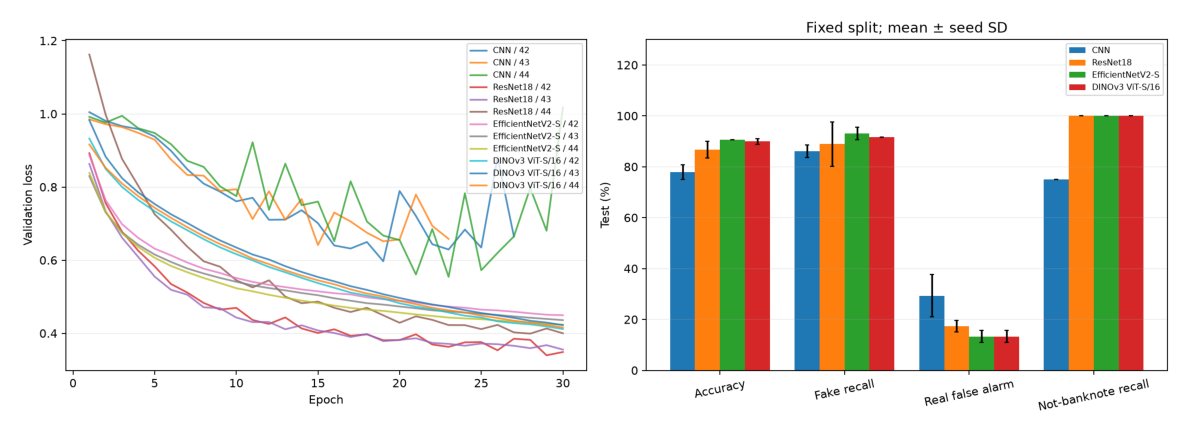

/Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/confusion_matrices.png


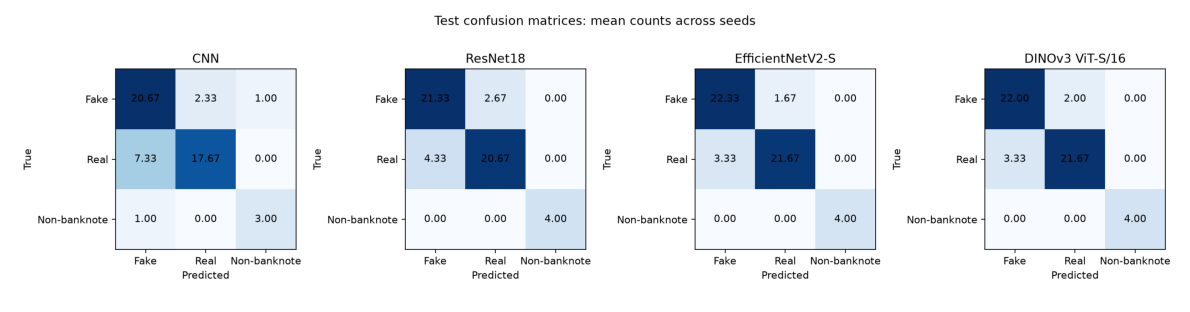

In [30]:
for name in ("comparison.png", "confusion_matrices.png"):
    path = run_root / name
    print(path.resolve())
    plt.figure(figsize=(12, 5))
    plt.imshow(read_rgb(path))
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### 6.10 Inspect photos where the models disagree

In the recorded comparison on the expanded test set EfficientNetV2-S gained **4.17 percentage points in fake recall** over ResNet18 and lowered the real-note false-alarm rate by **4.00 points**. Against DINOv3 its recall gain was **1.39 points** and both flagged **13.33%** of real notes.

**Can two models have the same accuracy while missing different notes?** Use seed 42, where the recorded EfficientNet and DINOv3 runs both got 48 of 53 right. The first panel shows the first fake-labelled note in roster order that EfficientNet caught and DINOv3 missed. The second shows the reverse. Use the image paths to find the examples in the dataset folder. The table below also shows the CNN and ResNet18 predictions for the first six errors across the four models.

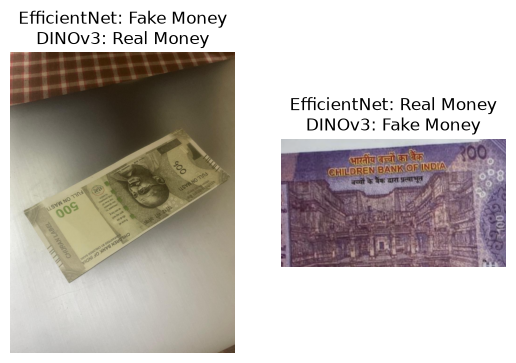

,label,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Fake Money,Real Money
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Real Money,Fake Money


,label,CNN,ResNet18,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,,,
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Fake Money,Fake Money,Real Money,Fake Money
test/fake money/500_92c7017763de5a1b.jpg,Fake Money,Real Money,Real Money,Fake Money,Fake Money
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Real Money,Fake Money,Fake Money,Real Money
test/fake money/500_c8ec7e37f9739637.jpg,Fake Money,Fake Money,Fake Money,Fake Money,Real Money
test/fake money/2000_6ed5ae16eb6d0ce8.png,Fake Money,Not a Banknote,Fake Money,Fake Money,Fake Money
test/OR money/100_f5a765f1ce4bb123.jpg,Real Money,Fake Money,Real Money,Real Money,Real Money


In [31]:
cases = paths.loc[paths["split"] == "test", ["split_path", "label"]].set_index("split_path")
for run in results["runs"]:
    if run["seed"] == 42:
        predictions = {}
        for photo in run["test_predictions"]:
            file = Path(photo["path"])
            predictions[f"test/{file.parent.name}/{file.name}"] = names[photo["predicted_label"]]
        cases[MODEL_NAMES[run["architecture"]]] = predictions

# Show one fake note caught only by EfficientNet and one caught only by DINOv3 in this pair.
fake = cases.loc[cases["label"] == "Fake Money", ["label", "EfficientNetV2-S", "DINOv3 ViT-S/16"]]
efficient = fake["EfficientNetV2-S"] == "Fake Money"
dino = fake["DINOv3 ViT-S/16"] == "Fake Money"
pair = pd.concat([fake[efficient & ~dino].head(1), fake[dino & ~efficient].head(1)])
if not pair.empty:
    show_photos(pair.index, "EfficientNet: " + pair["EfficientNetV2-S"] + "\nDINOv3: " + pair["DINOv3 ViT-S/16"])
display(pair)

# Show the first six photos that at least one model got wrong.
predictions = cases[[MODEL_NAMES[arch] for arch in archs]]
wrong = predictions.ne(cases["label"], axis="index").any(axis=1)
display(cases.loc[wrong, ["label", *predictions.columns]].head(6))

## 7. Why did the model ranking change?

The original four-model comparison used **65 train / 12 validation / 12 test**. Each test class contained four images. One more correct prediction changed single-seed accuracy by **8.33 percentage points**. The expanded comparison used **187 / 38 / 53**, with **44 of 53 test images** from the 500- and 2000-rupee folders. Four non-banknote test photos occur in both sets. The 18-image pilot used in the CAM lab is a third, separate experiment.

This historical comparison always uses the archived checkpoints. Read the table from left to right. The first two columns score different fits on the same old test set. The last two columns score **the very same expanded-data checkpoints** on different test sets. Every entry averages seeds 42, 43 and 44. [Original completed-run log](runs/course_models_archive_v3/rank_check/original_four_model_run.log) · [Checkpoint hashes and paired predictions](runs/course_models_archive_v3/rank_check/fixed_checkpoint_test.json)


In [27]:
rank_dir = COMPARISON / "rank_check"
rank = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
accuracy = pd.DataFrame({
    "Original fit → old test": {m: rank["historical"][m]["accuracy"]["mean"] for m in archs},
    "Expanded fit → old test": {m: rank["fixed_checkpoint_means"][m]["old"]["accuracy"] for m in archs},
    "Expanded fit → new test": {m: rank["fixed_checkpoint_means"][m]["new"]["accuracy"] for m in archs}})
display((100 * accuracy.rename(index=MODEL_NAMES)).round(2).rename_axis("Accuracy (%)"))


,Original fit → old test,Expanded fit → old test,Expanded fit → new test
Accuracy (%),,,
CNN,55.56,77.78,77.99
ResNet18,83.33,63.89,86.79
EfficientNetV2-S,80.56,66.67,90.57
DINOv3 ViT-S/16,88.89,61.11,89.94


**Read across one row first.** DINOv3 scored 88.89% in the original run. After fitting on the expanded data it scored 61.11% on those same 12 photographs. With those expanded weights held fixed, it scored 89.94% on the new 53. Changing the fit had already reversed the order of EfficientNet and DINOv3 on the old images. Training photographs, validation images and device (CPU to MPS) changed together.

**Now count the difference in photographs.** Across the three seeds, EfficientNet and DINOv3 got 48 vs 48, 48 vs 47 and 48 vs 48 correct. Over those repeated predictions EfficientNet gained two correct decisions on 500-rupee images and two on 2000-rupee images, and lost three on 100-rupee images. That leaves **one additional correct decision**. There were only two 100-rupee photographs. Compared with ResNet18, the corresponding differences were +6, +2 and −2.

**What would you report?** EfficientNet led on expanded-test accuracy and fake recall. DINOv3 was close. ResNet18 led on mean validation accuracy (83.33%). The old-test overlap check found no exact, known-group or near-hash match to expanded training or validation. The photographed notes lack verified physical IDs. **Part 2** uses the earlier, fixed ResNet18 checkpoint so that its CAM measurements can be reproduced.

# Part 2 · What did the classifier respond to?

EfficientNetV2-S caught the most fake-labelled notes on average in Part 1. Here we use the earlier ResNet18 because the recorded missed decision, heatmaps and regional measurements all come from that checkpoint.

Start with the prediction and two heatmaps (Sections 8–10). The project's contribution begins in Section 11. Edit one region at a time to measure whether its pixels support Fake or Real. Section 12 compares the location selected by Score-CAM with the location selected by a pixel test, using a different filter to check both. Section 13 compares the two baseline heatmaps across the pilot validation set.

## 8. Which class did ResNet18 choose?

Before looking at a heatmap, record what the pilot ResNet18 predicts for the original photo. The default example is a 100-rupee image from the fake-labelled test folder. Compare that folder label with the model's highest-scoring class.

### 8.1 Choose the photograph and model settings

Start with `IMAGE`, the file the classifier will see. `TestTransform("resnet18")` selects the same full-frame preprocessing used in the current notebook. The checksum identifies the saved model weights. `METHODS` and `RECORDS` are settings for later experiments. To try another photo, change `IMAGE` and rerun Sections 8–10.

In [28]:
IMAGE = PILOT_DATA / "test/fake money/100_4b6f91bfcd036823.png"
METHODS = ["gradcam", "scorecam"]
RECORDS = Path("runs/input_region_audit_v1/test/samples")
WEIGHT_SHA256 = "720a18ec4c49f2a7bdb7459d2653b1653567d3a9a3a43cb0c11e9e9803846a7c"
cam_transform = TestTransform("resnet18")

### 8.2 Prepare the input and define how to score it

Read the three helpers in order. `file_sha256` computes a file fingerprint so we can check which weights we loaded. `prepare_photo` resizes and pads the photo, then adds a batch dimension. Its output has shape (1, 3, 224, 224), and the saved bounds tell us where the photo ends and the padding begins. `score_batches` returns the model's raw scores (logits) and uses softmax to convert them to three probabilities.

In [29]:
def file_sha256(path):
    """Compute a file's SHA-256 digest for checking image, model and protocol identities."""
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def prepare_photo(path):
    """Prepare one pilot photo as a batch and keep its bounds for the pixel experiments."""
    tensor, geometry = cam_transform.with_geometry(read_rgb(path))
    return tensor.unsqueeze(0), geometry


@torch.no_grad()
def score_batches(model, tensors, batch_size):
    """Run the fixed classifier on each batch in order."""
    logits = torch.cat([model(batch) for batch in tensors.split(batch_size)])
    return {"logits": logits.tolist(), "probabilities": logits.softmax(dim=1).tolist()}

### 8.3 Run the classifier and read its decision

Check the weights and class order, then pass the photo through the frozen model once. Read the printed prediction and find its row in the probability table. The largest of the three probabilities wins, even when it is below 50%.

In [30]:
# Use the same model builder and checkpoint loader as in the classification experiment.
assert file_sha256(RESNET) == WEIGHT_SHA256
cam_model, cam_checkpoint = load_checkpoint(RESNET, "cpu")
assert cam_checkpoint["class_to_idx"] == CLASS_TO_IDX
cam_model.requires_grad_(False)
x, geometry = prepare_photo(IMAGE)

original = score_batches(cam_model, x, 16)
probabilities = original["probabilities"][0]
print("Input:", IMAGE.resolve())
print("Checkpoint:", RESNET.resolve())
print("Prediction:", names[np.argmax(probabilities)])
display(pd.Series(probabilities, index=names, name="Class probability").round(3).to_frame())

Input: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/100_4b6f91bfcd036823.png
Checkpoint: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/archive_pilot_v2/resnet18/best.pt
Prediction: Real Money


,Class probability
Fake Money,0.486
Real Money,0.495
Not a Banknote,0.020


**What happened on the default photo?** The saved output shows 49.5% for Real Money, 48.6% for Fake Money and 2.0% for Not a Banknote (rounded). ResNet18 narrowly chose Real. Against the dataset's provisional Fake label, this counts as a missed fake.

Section 9 deliberately asks Grad-CAM and Score-CAM to explain the **Fake** score on this same photo. This lets us inspect where the model found a response for the class it missed. The prediction recorded here remains Real.

## 9. Compare two explanations of the same Fake-class score

Keep the photograph, ResNet18, layer and target fixed. Grad-CAM uses gradients to weight feature maps. Score-CAM uses forward scores from masked inputs. Our regional pixel experiment begins in Section 11.

**Question.** If a heatmap is warm over the printed text, what does that observation let you test? Choose one location in the model-input panel and find it in each overlay. Colors are normalized separately for each method. A flat map cannot order locations on this photograph.

### Generate the overlays

For both overlays, class index 0 requests the Fake logit. The square includes the model's letterbox padding. Only pixels inside the photograph count towards the ranking test in Section 10.

In [31]:
def input_rgb(x):
    """Undo ImageNet normalization to display the ResNet18 input."""
    rgb = x[0].permute(1, 2, 0).detach().cpu().numpy()
    return np.clip(rgb * IMAGENET_STD + IMAGENET_MEAN, 0, 1)


def generate_cam(model, x, target, method, batch_size):
    """Explain the chosen class at layer2 of the frozen CPU ResNet18."""
    start = time.perf_counter()
    cam_class = {"gradcam": GradCAM, "scorecam": ScoreCAM}[method]
    # Grad-CAM differentiates the target score. Score-CAM only needs forward passes.
    use_grad = method == "gradcam"
    image = x.detach().requires_grad_(use_grad)
    with cam_class(model=model, target_layers=[model.layer2[-1]]) as cam:
        cam.batch_size = batch_size
        with torch.set_grad_enabled(use_grad):
            heatmap = cam(image, targets=[target])[0]
    model.zero_grad(set_to_none=True)
    return heatmap, time.perf_counter() - start


def valid_content_mask(geometry, shape):
    """Mark the photographic pixels inside the letterboxed input."""
    left, top, right, bottom = geometry["content_box_xyxy"]
    mask = np.zeros(shape, dtype=bool)
    mask[top:bottom, left:right] = True
    return mask

In [32]:
def cam_overlay(rgb, heatmap):
    """Color a normalized CAM with OpenCV and blend it with the RGB photograph."""
    pixels = np.rint(np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    intensity = np.rint(np.clip(heatmap, 0, 1) * 255).astype(np.uint8)
    colors = cv2.applyColorMap(intensity, cv2.COLORMAP_TURBO)
    colors = cv2.cvtColor(colors, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(pixels, 0.55, colors, 0.45, 0)


def plot_maps(rgb, maps, seconds, title, flat):
    """Display the input and the two CAM overlays."""
    fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3.4 * (len(maps) + 1), 3.7))
    axes[0].imshow(rgb)
    axes[0].set_title("Model input")
    for ax, (method, heatmap) in zip(axes[1:], maps.items()):
        view = rgb if flat[method] else cam_overlay(rgb, heatmap)
        ax.imshow(view)
        status = "flat map" if flat[method] else f"{seconds[method]:.2f} s"
        ax.set_title(f"{method}\n{status}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    fig.text(.5, .02, "Color scale is relative within each map.", ha="center", fontsize=8)
    fig.tight_layout(rect=(0, .06, 1, .95))
    plt.show()

100%|██████████| 8/8 [00:02<00:00,  2.93it/s]


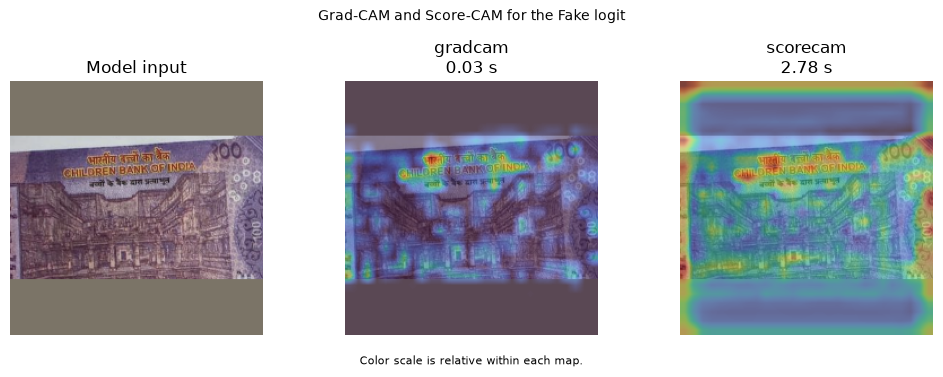

In [33]:
rgb = input_rgb(x)
valid = valid_content_mask(geometry, tuple(x.shape[-2:]))
heatmaps, cam_seconds = {}, {}
for method in METHODS:
    heatmaps[method], cam_seconds[method] = generate_cam(cam_model, x, ClassifierOutputTarget(0), method, 16)
flat = {method: np.ptp(heatmap[valid]) < 1e-7 for method, heatmap in heatmaps.items()}
plot_maps(rgb, heatmaps, cam_seconds, "Grad-CAM and Score-CAM for the Fake logit", flat)

## 10. Does editing the hottest part change the score?

Imagine covering the most highly ranked 10% of photographic pixels. If those pixels support Fake, $P(\mathrm{Fake})$ should fall. Deletion repeats this edit in 10% steps. Insertion starts with the mean-color image and restores the same pixels in the same order. Both use the same 16-pixel grid and pixel budgets.

**Read the two columns separately.** Favor a smaller deletion area under the curve (AUC) and a larger insertion AUC. Compare each usable CAM with the seeded random block order on this image. Padding stays fixed throughout.

In [34]:
def make_blocks(valid, block_size):
    """Fixed model-input grid, intersected with the actual content rectangle."""
    height, width = valid.shape
    blocks = []
    for y in range(0, height, block_size):
        for x in range(0, width, block_size):
            y1, x1 = min(y + block_size, height), min(x + block_size, width)
            yy, xx = np.where(valid[y:y1, x:x1])
            indices = ((yy + y) * width + xx + x).astype(np.int64)
            if len(indices):
                blocks.append(indices)
    return blocks


def ranked_pixels(heatmap, blocks):
    """Rank by block-mean CAM; resolve ties by fixed row-major block index."""
    flat = heatmap.reshape(-1)
    means = np.array([flat[b].mean() for b in blocks], dtype=np.float64)
    order = np.argsort(-means, kind="stable")
    return np.concatenate([blocks[i] for i in order])


def random_pixels(blocks, image_sha256, repeat, seed):
    """Stable random block orders, independent of the method and target map."""
    rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_sha256[:8], 16), repeat]))
    order = rng.permutation(len(blocks))
    return np.concatenate([blocks[i] for i in order])

In [35]:
def make_replacement(x, geometry, baseline, blur_kernel, blur_sigma):
    """Keep padding fixed. Blur content separately so padding cannot bleed into it."""
    replacement = x.detach().clone()
    left, top, right, bottom = geometry["content_box_xyxy"]
    if baseline == "mean":
        replacement[:, :, top:bottom, left:right] = 0  # ImageNet mean RGB after normalization.
    elif baseline == "blur":
        content = x[0, :, top:bottom, left:right].detach().cpu().permute(1, 2, 0).numpy()
        blurred = cv2.GaussianBlur(content, (blur_kernel, blur_kernel), blur_sigma,
                                   borderType=cv2.BORDER_REFLECT_101)
        replacement[0, :, top:bottom, left:right] = torch.from_numpy(
            np.ascontiguousarray(blurred.transpose(2, 0, 1))).to(x.device, x.dtype)
    else:
        raise ValueError(f"Unknown replacement baseline: {baseline}")
    return replacement


def deletion_insertion_auc(model, x, replacement, pixel_order, fractions,
                          original, reference, target_index, batch_size):
    """Compute both AUCs using the same ranked pixels and the same area at each step."""
    counts = np.rint(fractions * len(pixel_order)).astype(int)
    actual = counts / len(pixel_order)
    # Deletion replaces the selected pixels. Insertion restores those same pixels.
    states = []
    for start, fill in [(x, replacement), (replacement, x)]:
        for count in counts[1:-1]:
            indices = torch.as_tensor(pixel_order[:count], device=x.device)
            edited = start.detach().clone()
            edited.flatten(2)[:, :, indices] = fill.flatten(2)[:, :, indices]
            states.append(edited)

    scores = score_batches(model, torch.cat(states), batch_size)
    middle = np.asarray(scores["probabilities"])[:, target_index]
    deletion, insertion = np.split(middle, 2)
    photo = original["probabilities"][0][target_index]
    baseline = reference["probabilities"][0][target_index]
    deletion_auc = np.trapezoid(np.r_[photo, deletion, baseline], x=actual)
    insertion_auc = np.trapezoid(np.r_[baseline, insertion, photo], x=actual)
    return float(deletion_auc), float(insertion_auc)

In [36]:
blocks = make_blocks(valid, 16)
replacement = make_replacement(x, geometry, "mean", 31, 10)
reference = score_batches(cam_model, replacement, 16)
fractions = np.linspace(0, 1, 11)
random_order = random_pixels(blocks, file_sha256(IMAGE), 0, 42)

orders = {"Random blocks": random_order}
for method in METHODS:
    if not flat[method]:
        orders[method] = ranked_pixels(heatmaps[method], blocks)

auc_rows = []
for method, order in orders.items():
    deletion, insertion = deletion_insertion_auc(
        cam_model, x, replacement, order, fractions, original, reference, 0, 16
    )
    auc_rows.append({"Ordering": method, "Deletion AUC": deletion, "Insertion AUC": insertion})
display(pd.DataFrame(auc_rows).set_index("Ordering").round(3))
print("Flat maps excluded from spatial ranking:", [m for m in METHODS if flat[m]])

,Deletion AUC,Insertion AUC
Ordering,,
Random blocks,0.575,0.421
gradcam,0.310,0.619
scorecam,0.376,0.489


Flat maps excluded from spatial ranking: []


Compare each CAM with the random ordering in the table. Lower deletion AUC and higher insertion AUC indicate a better ordering under this edit.

## 11. Our method · Check whether a small region favors Fake or Real

A heatmap nominates locations. Here we make a separate, measurable prediction about direction. Let $M=z_{Fake}-z_{Real}$. Edit one region in the original image and compute $M(\mathrm{original})-M(\mathrm{edited})$. A positive drop means that weakening the region moved the model toward Real. For the example tables, `fake_real_score` displays $100\,\mathrm{sigmoid}(M)$ on a 0–100 scale.

Use the current image tensor for both the Fake–Real Score-CAM and the regional edits. Read the measured directions in the table below.

### 11.1 Compare equal areas

The recorded candidates split each parent region into four equal-area corners and omit any odd center strip. Each candidate has three control boxes of the same shape. Below, we check the coordinates before filtering. Section 11.5 checks that the four candidates have equal area before comparing them.

In [37]:
OPERATIONS = ("median5", "lab_morph3")


def checked_box(box, shape):
    """Check the recorded box once before using it to edit the image."""
    left, top, right, bottom = map(int, box)
    height, width = shape
    if not (0 <= left < right <= width and 0 <= top < bottom <= height):
        raise ValueError("Pixel box outside input")
    return left, top, right, bottom

### 11.2 Change one region and keep the surrounding image fixed

The median filter smooths each color channel. The morphological filter smooths light and dark detail on the LAB lightness channel. Compare the two edits to see whether the direction survives a different way of weakening local texture.

In [38]:
def smooth_lightness(patch, kernel=3):
    """Weaken fine detail by averaging an opening and a closing on the LAB lightness channel."""
    # Convert the normalized RGB patch to the 8-bit color space expected by OpenCV.
    rgb = np.clip(patch * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    lab = cv2.cvtColor(np.rint(rgb * 255).astype(np.uint8), cv2.COLOR_RGB2LAB)

    element = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    lightness = lab[:, :, 0]
    opened = cv2.morphologyEx(lightness, cv2.MORPH_OPEN, element)
    closed = cv2.morphologyEx(lightness, cv2.MORPH_CLOSE, element)
    lab[:, :, 0] = np.rint((opened.astype(np.float32) + closed) / 2).astype(np.uint8)

    filtered = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB).astype(np.float32) / 255
    return (filtered - IMAGENET_MEAN) / IMAGENET_STD

In [39]:
def edit_pixels(x, box, operation):
    """Edit only the selected pixels, without changing image geometry."""
    left, top, right, bottom = box
    patch = x[0, :, top:bottom, left:right].detach().cpu().permute(1, 2, 0).numpy()
    if operation == "median5":
        filtered = cv2.medianBlur(np.ascontiguousarray(patch, dtype=np.float32), 5)
    elif operation == "lab_morph3":
        filtered = smooth_lightness(patch)
    else:
        raise ValueError(f"Unknown pixel operation: {operation}")

    changed = x.detach().clone()
    changed[0, :, top:bottom, left:right] = torch.as_tensor(
        filtered, device=x.device, dtype=x.dtype
    ).permute(2, 0, 1)

    return changed

### 11.3 Decide which directions the controls support

For each filter, subtract the median drop at the three controls from the candidate's drop. A qualifying effect must clear both the raw floor and the control-adjusted threshold in the same direction. Both filters qualifying in the positive direction gives **Supports Fake**. Both negative gives **Supports Real**. Opposite qualifying directions give **Operator conflict**. All other combinations give **Insufficient evidence**.

In [40]:
def grade_pixels(raw, controls, floor=.02, mad_multiplier=1.5):
    """Require both operators to agree and exceed same-shape control effects.

    Shapes: raw [regions, 2], controls [regions, 2, 3]. MAD estimates variation
    between control locations; the fixed floor also rejects negligible effects.
    """
    center = np.median(controls, axis=2)
    mad = np.median(np.abs(controls - center[:, :, None]), axis=2)
    contrast = raw - center
    threshold = np.maximum(floor, mad_multiplier * 1.4826 * mad)
    # Positive means that removing detail shifted the model away from Fake.
    directions = np.zeros(raw.shape, dtype=int)
    directions[(raw >= floor) & (contrast >= threshold)] = 1
    directions[(raw <= -floor) & (contrast <= -threshold)] = -1
    states = np.full(len(raw), "insufficient_pixel_evidence", dtype="<U32")
    states[(directions > 0).any(1) & (directions < 0).any(1)] = "pixel_operator_conflict"
    states[np.all(directions == 1, axis=1)] = "pixel_supports_fake_direction"
    states[np.all(directions == -1, axis=1)] = "pixel_supports_real_direction"
    return {
        "raw_margin_drops": raw,
        "control_margin_drops": controls,
        "control_medians": center,
        "control_mad": mad,
        "control_adjusted_drops": contrast,
        "control_thresholds": threshold,
        "operation_directions": directions,
        "pixel_states": states,
    }

### 11.4 Measure the change in the classifier

Score the original and edited images in a fixed batch order. Reuse repeated edits when candidate and control boxes overlap exactly. A positive drop in the Fake minus Real margin means the original pixels supported Fake under this edit.

In [41]:
def measure_pixels(model, x, regions, original_score):
    """Measure how each local edit changes the Fake minus Real logit margin.

    Compare each region with three same-shape controls under both filters.
    Return the measured drops, directions and logits after each regional edit.
    A positive drop means the edit moved the model toward Real relative to Fake.
    """
    inputs = [x]
    unique_edits, lookup = {}, []
    for region in regions:
        boxes = [checked_box(b, x.shape[-2:]) for b in [region["box"], *region["controls"]]]
        sizes = {(r - l, b - t) for l, t, r, b in boxes}
        assert len(boxes) == 4 and len(sizes) == 1, "Use three controls of the same shape"
        region_indices = []
        for operation in OPERATIONS:
            indices = []
            for box in boxes:
                key = (operation, box)
                if key not in unique_edits:
                    unique_edits[key] = len(inputs)
                    inputs.append(edit_pixels(x, box, operation))
                indices.append(unique_edits[key])
            region_indices.append(indices)
        lookup.append(region_indices)

    # Preserve deduplication order and batch size: rebatching can shift logits.
    scores = score_batches(model, torch.cat(inputs), 16)
    logits = np.asarray(scores["logits"], float)
    margins = logits[:, 0] - logits[:, 1]
    baseline = float(margins[0])
    single = original_score["logits"][0]
    precision = abs(baseline - (single[0] - single[1]))
    floor = max(.02, 10 * precision)
    lookup = np.asarray(lookup)
    drops = baseline - margins[lookup]
    measured = grade_pixels(drops[:, :, 0], drops[:, :, 1:], floor)
    measured["roi_logits_after"] = logits[lookup[:, :, 0]]
    measured["control_logits_after"] = logits[lookup[:, :, 1:]]
    return measured

### 11.5 Select with one operator and check with the other

Score-CAM selects the quarter with the highest mean heat. Pixel verification selects the quarter with the largest control-adjusted margin drop. Read the other operator’s effect only after selecting each location.

**Keep the second edit for checking.** Suppose the median filter selects a quarter because it produced the largest drop there. Scoring it again with that same filter would reward the rule used to pick it. Read the morphological result only after both selections are fixed. The stored comparisons also reverse the roles of the two filters.

In [42]:
def mean_cam_in_regions(heatmap, regions):
    """Read the average Score-CAM response in each candidate box."""
    values = np.asarray(heatmap, dtype=float)
    means = []
    for region in regions:
        left, top, right, bottom = region["box"]
        means.append(values[top:bottom, left:right].mean())
    return np.asarray(means)


def cross_operator_choices(measured, cam_scores, regions):
    """Compare Score-CAM selection with measured selection at equal pixel area.

    The held-out operator is never used for selection or tie breaking. This is a
    local comparison between four candidates, not a full-image CAM ranking.
    """
    contrast = np.asarray(measured["control_adjusted_drops"], float)
    raw = np.asarray(measured["raw_margin_drops"], float)
    cam_scores = np.asarray(cam_scores)
    # Compare only the four quarters of the same parent region.
    groups = {}
    for i, region in enumerate(regions):
        parent = int(region["parent_index"])
        groups.setdefault(parent, []).append(i)

    records = []
    for parent, rows in sorted(groups.items()):
        rows.sort(key=lambda i: int(regions[i]["child_index"]))
        areas = []
        for i in rows:
            left, top, right, bottom = regions[i]["box"]
            areas.append((right - left) * (bottom - top))
        if len(rows) != 4 or len(set(areas)) != 1:
            raise ValueError("Need four equal-area quarters per parent")

        # Score-CAM picks the same box for both trials. The pixel-based choice depends on the filter.
        cam_choice = rows[np.argmax(cam_scores[rows])]
        for screen, heldout in [(0, 1), (1, 0)]:
            pixel_choice = rows[np.argmax(contrast[rows, screen])]
            choices = {"scorecam": cam_choice, "input_screen": pixel_choice}
            outcomes = {
                name: {"control_adjusted_drop": float(contrast[index, heldout]),
                       "raw_drop": float(raw[index, heldout])}
                for name, index in choices.items()
            }
            records.append({
                "parent_index": parent,
                "screen_operator": OPERATIONS[screen],
                "heldout_operator": OPERATIONS[heldout],
                "candidate_indices": rows,
                "selected_indices": choices,
                "heldout_results": outcomes,
            })
    return records

### 11.6 Apply the check to the 100-rupee note

First read the orange and blue boxes on the right. Compare both edited scores in each table row with the original score printed above it. Region labels start at R1. Only regions with a measured direction or an operator conflict are drawn. The printed OCR text is a separate observation for a human reviewer.

In [43]:
def load_sample(record_path):
    """Reuse the saved candidate coordinates and compute Score-CAM on the current pixels."""
    saved = json.loads(record_path.read_text())
    image_path = PILOT_DATA / saved["destination"]
    assert file_sha256(image_path) == saved["sha256"]
    tensor, _ = prepare_photo(image_path)
    def fake_minus_real(logits):
        return logits[0] - logits[1]
    cam, _ = generate_cam(cam_model, tensor, fake_minus_real, "scorecam", 16)
    return saved, tensor, cam

In [44]:
def replay_case(filename):
    """Repeat the local pixel edits on the OpenCV-resized input."""
    saved, tensor, cam = load_sample(RECORDS / filename)
    print("Regional case:", (PILOT_DATA / saved["destination"]).resolve())
    regions = saved["regions"]
    scores = score_batches(cam_model, tensor, 16)
    measured = measure_pixels(cam_model, tensor, regions, scores)
    choices = cross_operator_choices(measured, mean_cam_in_regions(cam, regions), regions)

    return {
        "rgb": input_rgb(tensor), "cam": cam,
        "prediction": ["Fake", "Real", "Non-banknote"][np.argmax(scores["probabilities"][0])],
        "score": fake_real_score(scores["logits"][0]), "regions": regions,
        "measurements": measured, "choices": choices,
    }


def fake_real_score(logits):
    """Express the Fake minus Real logit margin on a 0–100 scale. Higher values favor Fake
    relative to Real.
    """
    logits = np.asarray(logits)
    return 100 / (1 + np.exp(-(logits[..., 0] - logits[..., 1])))

In [45]:
REGION_LABELS = {
    "pixel_supports_fake_direction": ("Supports Fake", (255, 140, 0)),
    "pixel_supports_real_direction": ("Supports Real", (30, 144, 255)),
    "pixel_operator_conflict": ("Operator conflict", (128, 0, 128)),
}


def region_figure(rgb, cam, regions, states, prediction):
    """Draw the baseline overlay and mark the regions with a measured direction or conflict."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.1))
    marked = np.ascontiguousarray(np.rint(rgb * 255), dtype=np.uint8)
    axes[0].imshow(cam_overlay(rgb, cam))
    for ax in axes:
        ax.axis("off")
    axes[0].set_title("Score-CAM · Fake minus Real")
    axes[1].set_title("Measured regional directions")
    for i, (region, state) in enumerate(zip(regions, states), start=1):
        if state in REGION_LABELS:
            _, color = REGION_LABELS[state]
            left, top, right, bottom = region["box"]
            cv2.rectangle(marked, (left, top), (right - 1, bottom - 1), color, 1)
            cv2.putText(marked, f"R{i}", (left, max(9, top - 2)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.32, color, 1, cv2.LINE_AA)
    axes[1].imshow(marked)
    fig.legend(handles=[Patch(color=np.array(color) / 255, label=text) for text, color in REGION_LABELS.values()],
               loc="lower center", ncol=3, fontsize=8)
    fig.suptitle(f"Original ResNet18 prediction: {prediction}")
    fig.tight_layout(rect=(0, .06, 1, .96))
    return fig

100%|██████████| 8/8 [00:02<00:00,  2.76it/s]


Regional case: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/100_4b6f91bfcd036823.png


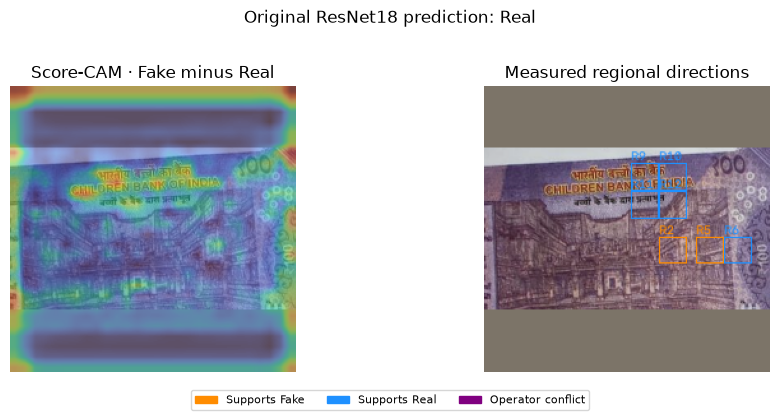

Original prediction: Real
Original fake-real score: 49.52/100


,Region,Direction,median5,lab_morph3
0,R2,Supports Fake,39.26,44.57
1,R5,Supports Fake,45.94,46.53
2,R6,Supports Real,54.02,50.84
3,R9,Supports Real,52.22,50.46
4,R10,Supports Real,54.28,52.31
5,R11,Supports Real,66.59,55.22
6,R12,Supports Real,56.39,52.75


Insufficient evidence: 5 of 12
Independent OCR: ['CHILDREN BANK OF INDIA']


In [46]:
case100 = replay_case("00_4b6f91bfcd03.json")
effects = case100["measurements"]
states = effects["pixel_states"]
region_figure(case100["rgb"], case100["cam"], case100["regions"], states, case100["prediction"])
plt.show()

region_rows = []
for i, state in enumerate(states):
    if state in REGION_LABELS:
        median, morph = fake_real_score(effects["roi_logits_after"][i])
        region_rows.append({"Region": f"R{i+1}", "Direction": REGION_LABELS[state][0],
                     "median5": median, "lab_morph3": morph})
print("Original prediction:", case100["prediction"])
print(f"Original fake-real score: {case100['score']:.2f}/100")
display(pd.DataFrame(region_rows).round(2))
print("Insufficient evidence:", np.count_nonzero(np.asarray(states) == "insufficient_pixel_evidence"), "of", len(states))

ocr_path = Path("runs/marker_swap_v1/samples/old_test__00_4b6f91bfcd03.json")
if ocr_path.is_file():
    ocr = json.loads(ocr_path.read_text())
    assert ocr["sha256"] == json.loads((RECORDS / "00_4b6f91bfcd03.json").read_text())["sha256"]
    print("Independent OCR:", [marker["text"] for marker in ocr["markers"]])

Compare each edited score with the original. A decrease indicates support for Fake under that edit. An increase indicates support for Real. Inspect the same-shape controls below before interpreting a region.

In [47]:
region_no = 2
control_columns = {"raw_margin_drops": "Raw drop", "control_medians": "Median control",
           "control_adjusted_drops": "Adjusted drop", "control_thresholds": "Threshold"}
control_check = pd.DataFrame({title: effects[key][region_no - 1] for key, title in control_columns.items()},
                             index=OPERATIONS)
display(control_check.round(3))

,Raw drop,Median control,Adjusted drop,Threshold
median5,0.417,-0.016,0.433,0.020
lab_morph3,0.199,0.016,0.183,0.039


## 12. Does pixel verification select a more sensitive location?

In the recorded 2000-rupee example, compare two choices among four equal-area quarters of the same candidate. Score-CAM picks the highest mean heat. Our method picks the largest control-adjusted margin drop under the median filter. Use the **other** operator to check both selections.

This candidate was selected retrospectively to illustrate the experiment. The numbers below describe this particular location and edit.

100%|██████████| 8/8 [00:02<00:00,  2.97it/s]


Regional case: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/2000_37e2bd6dd602b4de.png


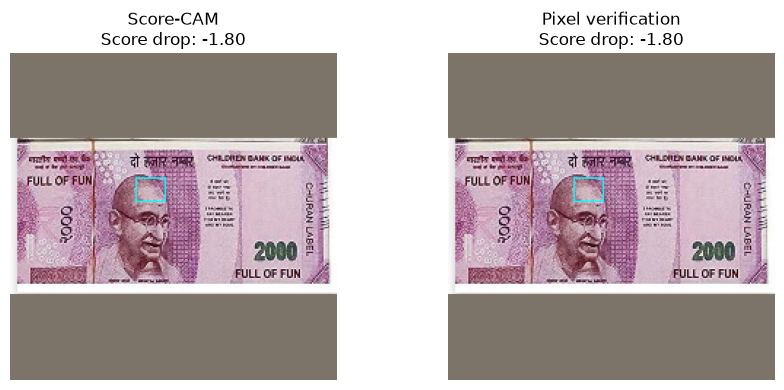

,Edited pixels,Before,After,Drop
Selection,,,,
Score-CAM,357,68.46,70.26,-1.8
Pixel verification,357,68.46,70.26,-1.8


In [48]:
case2000 = replay_case("02_37e2bd6dd602.json")
trial = next(row for row in case2000["choices"]
             if row["parent_index"] == 2 and row["screen_operator"] == "median5")
op = OPERATIONS.index(trial["heldout_operator"])
baseline = case2000["score"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
selection_rows = []
for ax, (method, idx) in zip(axes, trial["selected_indices"].items()):
    left, top, right, bottom = case2000["regions"][idx]["box"]
    after = fake_real_score(case2000["measurements"]["roi_logits_after"][idx][op])
    name = {"scorecam": "Score-CAM", "input_screen": "Pixel verification"}[method]
    marked = np.ascontiguousarray(np.rint(case2000["rgb"] * 255), dtype=np.uint8)
    cv2.rectangle(marked, (left, top), (right - 1, bottom - 1), (0, 255, 255), 1)
    ax.imshow(marked)
    ax.set_title(f"{name}\nScore drop: {baseline - after:.2f}")
    ax.axis("off")
    selection_rows.append({"Selection": name, "Edited pixels": (right-left)*(bottom-top),
                 "Before": baseline, "After": after, "Drop": baseline-after})
fig.tight_layout()
plt.show()
display(pd.DataFrame(selection_rows).set_index("Selection").round(2))

Compare the two drops under the held-out filter. A larger drop means the selected position influenced the Fake–Real score more strongly in this example.

## 13. Compare Grad-CAM and Score-CAM on the validation set

The default cell reads the archived per-image measurements from the earlier resize filter. Set `RUN_FULL_VALIDATION = True` at the top of the notebook to measure the current OpenCV inputs in memory. Both methods use the same 32 images, two pixel replacements and five random block orders per image. Compare deletion (lower is better) and insertion (higher is better) on images where both maps can rank locations.

In [49]:
def validation_rows(model, sample):
    """Measure both CAMs and matched random orders on one validation image."""
    path = PILOT_DATA / sample["destination"]
    if file_sha256(path) != sample["sha256"]:
        raise ValueError(f"Image has changed: {path}")
    x, geometry = prepare_photo(path)
    valid = valid_content_mask(geometry, tuple(x.shape[-2:]))
    blocks = make_blocks(valid, 16)
    original = score_batches(model, x, 16)
    orders = {}
    statuses = {}
    for method in METHODS:
        heat, _ = generate_cam(model, x, ClassifierOutputTarget(0), method, 16)
        statuses[method] = "flat" if np.ptp(heat[valid]) < 1e-7 else "ok"
        if statuses[method] == "ok":
            orders[method] = ranked_pixels(heat, blocks)
    random_orders = [random_pixels(blocks, sample["sha256"], i, 42)
                     for i in range(5)]

    rows = []
    for baseline in ("mean", "blur"):
        replacement = make_replacement(x, geometry, baseline, 31, 10)
        reference = score_batches(model, replacement, 16)

        def aucs(order):
            return deletion_insertion_auc(
                model, x, replacement, order, np.linspace(0, 1, 11), original, reference, 0, 16
            )

        random_del, random_ins = np.mean([aucs(order) for order in random_orders], axis=0)
        for method in METHODS:
            usable = method in orders
            deletion, insertion = aucs(orders[method]) if usable else (np.nan, np.nan)
            rows.append({"sample_id": sample["destination"], "method": method, "replacement": baseline,
                         "cam_status": statuses[method], "deletion_auc": deletion,
                         "insertion_auc": insertion, "random_deletion_auc": random_del,
                         "random_insertion_auc": random_ins})
    return rows

In [ ]:
validation_dir = Path("runs/cam_baselines_layer2_val_v1")
if RUN_FULL_VALIDATION:
    pilot_manifest = json.loads((PILOT_DATA / "manifest.json").read_text())
    assert pilot_manifest["class_to_idx"] == CLASS_TO_IDX
    validation_samples = [sample for sample in pilot_manifest["samples"] if sample["split"] == "val"]
    rows = []
    for i, sample in enumerate(validation_samples, start=1):
        print(f"{i}/{len(validation_samples)}  {sample['destination']}")
        rows.extend(validation_rows(cam_model, sample))
    validation = pd.DataFrame(rows)
else:
    print("Saved measurements for the pilot ResNet18 at layer2[-1]")
    validation = pd.concat([pd.read_csv(validation_dir / method / "metrics.csv").assign(method=method)
                            for method in METHODS], ignore_index=True)

# Count usable maps, then average only over image/replacement pairs usable for both methods.
usable = validation["cam_status"].eq("ok")
display(validation.assign(usable=usable).drop_duplicates(["method", "sample_id"])
        .groupby("method")["usable"].agg(["sum", "count"]).rename(columns={"sum": "Usable", "count": "Images"}))
paired = usable.groupby([validation["sample_id"], validation["replacement"]]).transform("sum").eq(len(METHODS))
columns = ["deletion_auc", "insertion_auc", "random_deletion_auc", "random_insertion_auc"]
display(validation.loc[paired].groupby(["replacement", "method"])[columns].mean().round(4))

Saved measurements for the pilot ResNet18 at layer2[-1]


,Usable,Images
method,,
gradcam,32,32
scorecam,32,32


deletion_auc  insertion_auc  random_deletion_auc  \
replacement method                                                       
blur        gradcam         0.3080         0.4521               0.3357   
            scorecam        0.2871         0.4434               0.3357   
mean        gradcam         0.2611         0.4094               0.3221   
            scorecam        0.2635         0.3889               0.3221   

                      random_insertion_auc  
replacement method                          
blur        gradcam                 0.3354  
            scorecam                0.3354  
mean        gradcam                 0.3304  
            scorecam                0.3304

## Optional exercise 1 · Follow a short training run and inspect the CAM checkpoint

Turn on `RUN_DEMOS` to fit the CNN for three epochs using the same training routine as the four-model comparison. The demo uses a temporary checkpoint directory. Read its validation loss together with fake recall. Then open the pilot model's confusion matrix and locate the missed fake-labelled file used in Section 11.


In [51]:
if RUN_DEMOS:
    with TemporaryDirectory() as demo_folder:
        _, demo = train(DEMO_EPOCHS, DATA, demo_folder, device=device, seed=SEED)
    history = pd.DataFrame([{"epoch": e["epoch"], "train_loss": e["train_loss"],
                             "val_loss": e["val"]["loss"], "val_fake_recall": e["val"]["fake_recall"]}
                            for e in demo["epochs"]]).set_index("epoch")
    display(history.round(3))
    history[["train_loss", "val_loss"]].plot(marker="o", ylabel="Cross-entropy loss", xticks=history.index)
    plt.show()

In [52]:
if RUN_DEMOS:
    test_data = MoneyDataset(PILOT_DATA / "test", transform=cam_transform)
    metrics, predictions = evaluate_split(cam_model, test_data, "cpu", BATCH_SIZE)

    print(f"Checkpoint epoch: {cam_checkpoint['epoch']} | Test images: {metrics['n']}")
    scores = ["accuracy", "fake_recall", "fake_fnr", "fake_precision", "real_false_alarm_rate"]
    display(pd.Series({key: metrics[key] for key in scores}, name="Test score").to_frame().round(3))
    # Rows are folder labels. Columns are model predictions.
    cm = pd.DataFrame(metrics["confusion_matrix"], index=names, columns=names)
    display(cm.rename_axis(index="Label", columns="Prediction"))

    # Show the specific files that contribute to the fake false-negative rate.
    misses = [str(Path(row["path"])) for row in predictions
              if row["true_label"] == 0 and row["predicted_label"] != 0]
    print("Missed fake-labelled images:", misses)

## Optional exercise 2 · Repeat the historical test comparison

Set `RECHECK_RANKING = True` to run the archived checkpoints on both test sets. For each model and seed, the table counts how many new predictions match the saved decisions on the same files.


In [53]:
if RECHECK_RANKING:
    replay = []
    for run in rank["runs"]:
        arch, seed = run["model"], run["seed"]
        model, _ = load_checkpoint(COMPARISON / arch / f"seed_{seed}" / "best.pt", "cpu")
        for key, folder in [("old", Path("dataset_threeclass")), ("new", DATA)]:
            images = MoneyDataset(folder / "test", transform=TestTransform(arch))
            _, predictions = evaluate_split(model, images, "cpu", BATCH_SIZE)
            expected = {p["path"]: p["prediction"] for p in run[key]}
            matches = sum(p["predicted_label"] == expected[str(Path(p["path"]).relative_to(folder))]
                          for p in predictions)
            replay.append({"Model": MODEL_NAMES[arch], "Seed": seed, "Test set": key,
                           "Matching decisions": matches, "Images": len(predictions)})
    display(pd.DataFrame(replay))
